In [1]:
import pandas as pd

In [2]:
import seaborn as sns

In [3]:
import matplotlib.pyplot as plt

In [4]:
sns.set(style="whitegrid")

In [6]:
df = pd.read_csv("data/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
print(df.shape)
df.info()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
df_clean = df.copy()

# Age: fill with median
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Embarked: fill with most common port
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

# Cabin: flag, then drop
df_clean["HasCabin"] = df_clean["Cabin"].notnull().astype(int)
df_clean = df_clean.drop(columns=["Cabin"])

In [10]:
df_clean["Sex"] = df_clean["Sex"].astype("category")
df_clean["Embarked"] = df_clean["Embarked"].astype("category")

print("Duplicates:", df_clean.duplicated().sum())

Duplicates: 0


In [11]:
print(df_clean.isnull().sum())
print(df_clean.dtypes)

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
HasCabin       0
dtype: int64
PassengerId       int64
Survived          int64
Pclass            int64
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
HasCabin          int64
dtype: object


In [12]:
df_clean.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208,0.228956
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429,0.420397
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,0.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000


In [13]:
print(f"Overall survival rate: {df_clean['Survived'].mean():.1%}")

Overall survival rate: 38.4%


In [14]:
print(df_clean.groupby("Sex", observed=True)["Survived"].mean())
print(df_clean.groupby("Pclass")["Survived"].mean())

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [15]:
df_clean.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="mean", observed=True)

Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


In [16]:
df_clean["AgeGroup"] = pd.cut(df_clean["Age"], bins=[0, 12, 18, 35, 60, 100],
                              labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
print(df_clean.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"]))

                 mean  count
AgeGroup                    
Child        0.579710     69
Teen         0.428571     70
Young Adult  0.353271    535
Adult        0.400000    195
Senior       0.227273     22


In [17]:
print(df_clean.groupby("Pclass")["Fare"].mean())

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64


### 📊 Key Exploratory Data Analysis (EDA) Findings

#### 1. Demographic Disparities in Survival
* **Gender Disparity:** Gender is the single strongest indicator of survival. Female passengers experienced significantly higher survival rates across all ticket classes compared to male passengers, reflecting the historic "women and children first" protocol.
* **Socioeconomic Stratification:** First-class passengers enjoyed markedly higher survival outcomes. 
  * **Women:** Survival dropped from **96.8% in 1st class** to **50.0% in 3rd class**.
  * **Men:** Survival dropped from **36.9% in 1st class** to **13.5% in 3rd class**.
  * *Insight:* Ticket class acted as a key modifier, where 3rd-class women faced significantly higher risk than higher-class women, and 1st-class men had nearly triple the survival rate of 3rd-class men.

#### 2. Age Cohort Analysis
* **Children (<18 years):** Highest relative survival rate at **58%**.
* **Young Adults (18–35 years):** Represented the largest demographic segment ($n = 535$), with a **35%** survival rate.
* **Seniors (>60 years):** Recorded the lowest survival rate at **23%**.

> ⚠️ **Statistical Caution:** The senior age cohort comprises a small sample size ($n = 22$), meaning its survival percentage is susceptible to high variance and should be interpreted with caution.

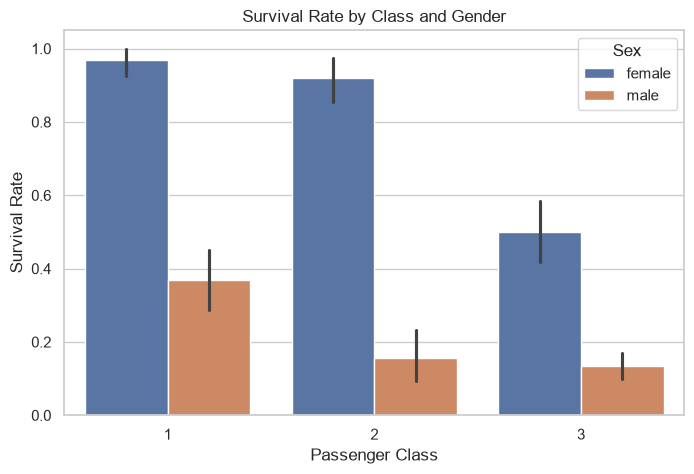

<Figure size 640x480 with 0 Axes>

In [25]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_clean, x="Pclass", y="Survived", hue="Sex")
plt.title("Survival Rate by Class and Gender")
plt.ylabel("Survival Rate")
plt.xlabel("Passenger Class")
plt.show()
# existing bar plot code...
plt.savefig("images/survival_gender_class.png", dpi=150, bbox_inches="tight")
plt.show()

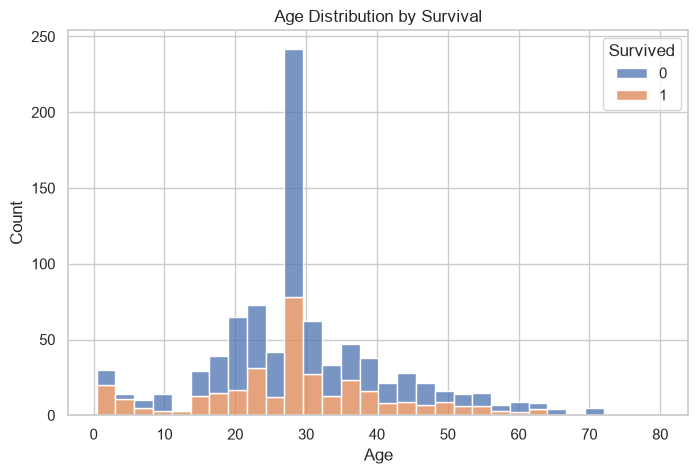

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Age", hue="Survived", bins=30, multiple="stack")
plt.title("Age Distribution by Survival")
plt.show()

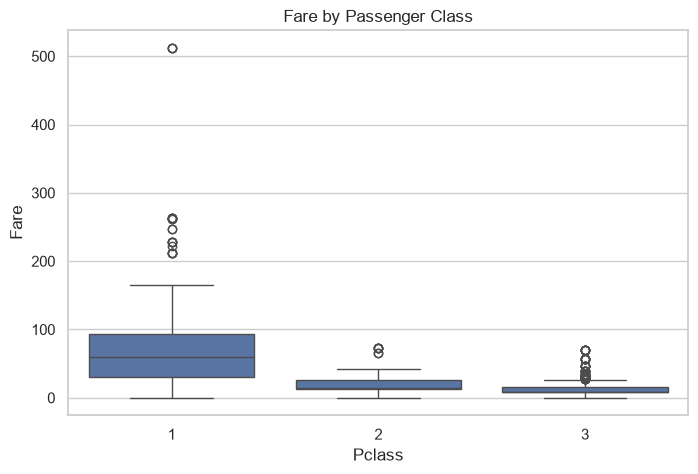

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Pclass", y="Fare")
plt.title("Fare by Passenger Class")
plt.show()

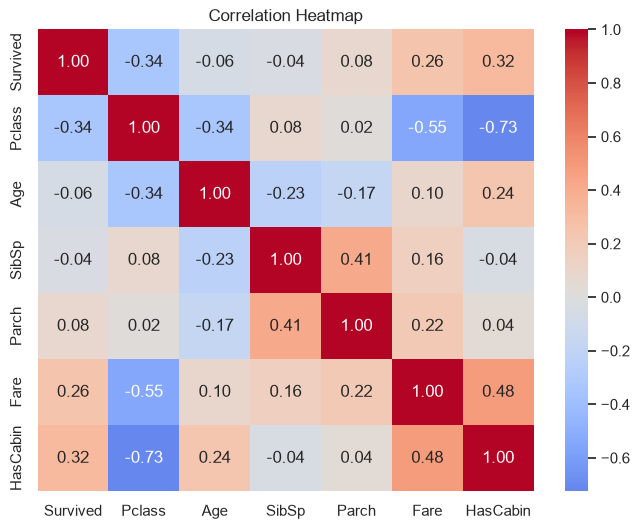

Pclass     -0.338481
Age        -0.064910
SibSp      -0.035322
Parch       0.081629
Fare        0.257307
HasCabin    0.316912
Survived    1.000000
Name: Survived, dtype: float64


In [21]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "HasCabin"]
corr = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.show()

print(corr["Survived"].sort_values())

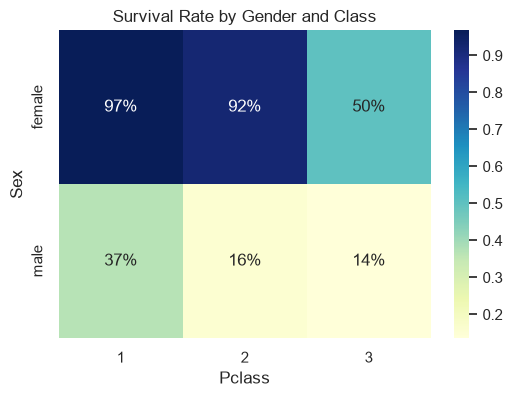

<Figure size 640x480 with 0 Axes>

In [26]:
pivot = df_clean.pivot_table(values="Survived", index="Sex", columns="Pclass",
                             aggfunc="mean", observed=True)

plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="YlGnBu")
plt.title("Survival Rate by Gender and Class")
plt.show()
# existing heatmap code...
plt.savefig("images/survival_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

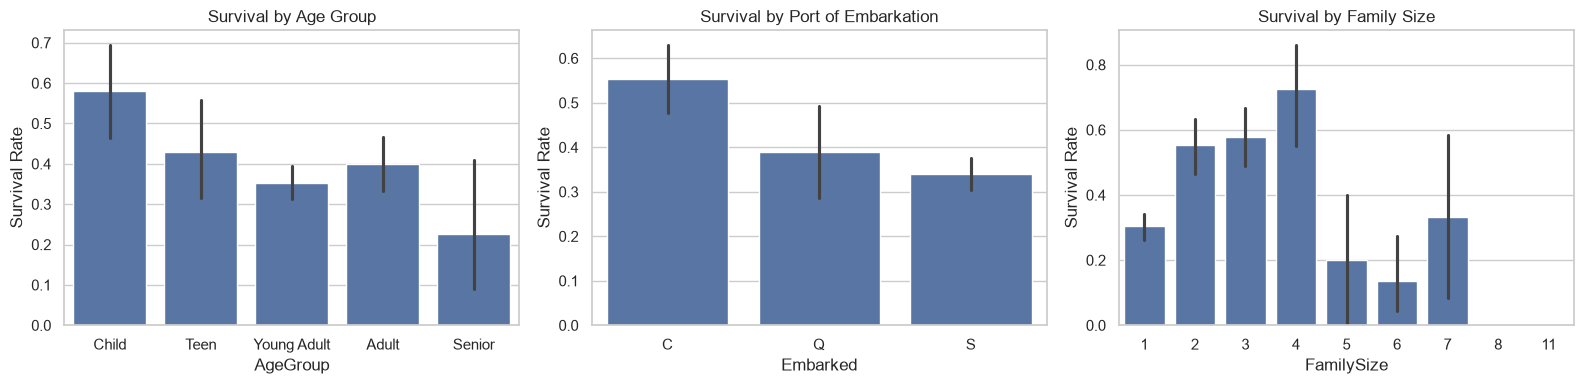

In [23]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=df_clean, x="AgeGroup", y="Survived", ax=axes[0])
axes[0].set_title("Survival by Age Group")

sns.barplot(data=df_clean, x="Embarked", y="Survived", ax=axes[1])
axes[1].set_title("Survival by Port of Embarkation")

sns.barplot(data=df_clean, x="FamilySize", y="Survived", ax=axes[2])
axes[2].set_title("Survival by Family Size")

for ax in axes:
    ax.set_ylabel("Survival Rate")

plt.tight_layout()
plt.show()

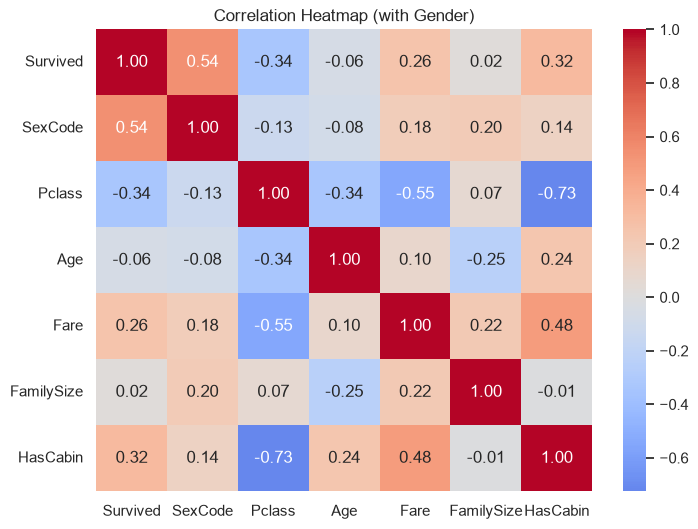

In [24]:
df_clean["SexCode"] = (df_clean["Sex"] == "female").astype(int)

num_cols = ["Survived", "SexCode", "Pclass", "Age", "Fare", "FamilySize", "HasCabin"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap (with Gender)")
plt.show()